<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex03_Hugging_Face_Transformer%EB%A7%9B%EB%B3%B4%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 구글 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 작업 경로 변경
%cd /content/drive/MyDrive/Colab Notebooks/딥러닝응용

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


### 1. Transformer 등장 배경
- 기존 RNN은 긴 문장을 처리할 때 앞부분 정보를 잃어버리는 장기 의존성 문제가 발생함
  - 장기 의존성 문제: 기울기 소실로 인해 먼저 입력된 과거 정보를 까먹는 현상
  - 시퀀스가 길어질수록 은닉층을 거쳐 과거 정보가 끝까지 온전히 전달되지 못하는 현상
  - 이를 완화하기 위해 LSTM, GRU가 등장했지만, 긴 문장 처리와 순차 연산에 따른 한계가 남아 Transformer로 발전함
- 데이터를 한 단계씩 순차적으로 처리하기 때문에 병렬화가 어렵고 학습·연산 속도가 느림
- 2017년 구글이 발표한 논문 *"Attention Is All You Need"*에서 제안된 모델이 Transformer임
  - 기존 Seq2Seq의 Encoder-Decoder 구조를 따르면서, RNN 대신 Attention을 중심으로 구현한 모델임
- Encoder, Decoder 역할
  - 인코더(Encoder): 입력 자연어 → 문맥 정보가 담긴 숫자(벡터) 표현으로 변환
  - 디코더(Decoder): 숫자(문맥 표현) → 출력 자연어로 생성
- Attention 작동 방식
  - 관련성 계산: 입력 데이터의 각 부분이 현재 처리할 작업과 얼마나 관련이 있는지 중요도 점수를 계산함
  - 가중치 부여: 계산된 중요도 점수에 따라 가중치를 매김
  - 정보 취합: 중요한 정보들을 모아 다음 단계로 전달함
  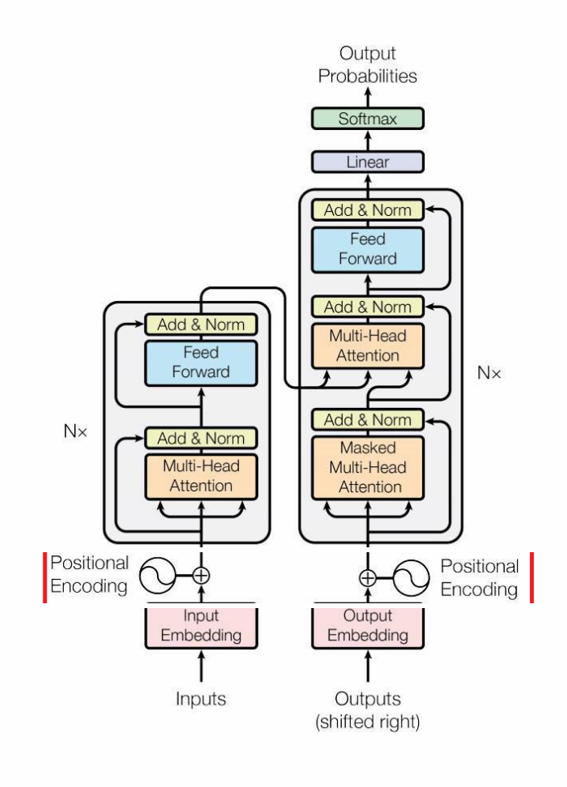

### 2. Transformer 구조
- Positional Encoding (위치 인코딩)
  - Attention 기반 모델은 입력 순서를 순차적으로 처리하지 못함
  - 이에 대해 토큰 간 순서 정보를 알려주기 위함 (한 문장을 병렬로 처리하면서도 각 단어의 위치를 인지하게 됨)
- Encoder Self-Attention
  - 인코더는 입력 문장의 모든 단어 간의 관계를 계산해서, 문장 전체에서 중요한 정보를 파악
- Add & Norm
  - 출력에 원래 입력을 더하고, 값을 정규화해서 안정된 학습을 할 수 있도록 도움
- Feed Forward
  - 활성화 함수를 사용해서 입력을 처리하고 비선형성을 통해 모델이 더 복잡한 패턴을 학습할 수 있게 만드는 완전 연결 신경망 (쉽게 이해하면 MLP)
- Decoder Masked Self-Attention
  - 디코더가 학습, 예측할 때 미래 단어를 참조하지 못하게 막아서, 이전 단어들을 사용해서 순차적으로 예측
- Encoder-Decoder Self-Attention
  - 디코더가 인코더의 출력을 참조해서, 입력 문장과의 관계를 기반으로 더 정확한 출력 생성

## 모델링 개발 방식과 실행 환경 비교

> Open API를 활용하는 방법 vs 직접 AI를 개발하는 방법

| 방법              | 장점                                         | 단점                                             |
| --------------- | ------------------------------------------ | ---------------------------------------------- |
| **Open API 활용** | - 빠른 개발<br>- 비용 절감<br>- 높은 신뢰성             | - 제한된 커스터마이징<br>- 사용량에 따른 비용 증가<br>- 데이터 보안 이슈 |
| **직접 AI 개발**    | - 커스터마이징 가능<br>- 장기적인 비용 절감<br>- 데이터 보안 강화 | - 많은 시간과 전문 지식 필요<br>- 지속적인 유지보수 필요            |

---

> 노코드 모델링 vs 코딩을 활용한 AI 개발

| 방법              | 장점                               | 단점                                 |
| --------------- | -------------------------------- | ---------------------------------- |
| **노코드 모델링**     | - 접근성<br>- 빠른 프로토타이핑<br>- 직관적 사용 | - 제한된 기능<br>- 유연성 부족<br>- 성능 저하 가능 |
| **코딩 활용 AI 개발** | - 유연성<br>- 고성능 모델<br>- 확장성       | - 전문 지식 필요<br>- 시간 소요<br>- 복잡성     |

---

> Make an AI from scratch vs Transfer learning

| 방법                          | 장점                                            | 단점                                  |
| --------------------------- | --------------------------------------------- | ----------------------------------- |
| **Make an AI from scratch** | - 완전한 커스터마이징<br>- 최적화<br>- 모델 이해도             | - 시간·비용 많이 소요<br>- 많은 데이터 필요        |
| **Transfer learning**       | - 시간 절약<br>- 적은 데이터로도 높은 성능<br>- 사전 학습된 모델 활용 | - 제한된 커스터마이징<br>- 적용 범위 제한<br>- 복잡성 |

---

> 웹 서버, 클라우드 환경 vs Edge Computing

| 방법                 | 장점                                   | 단점                                   |
| ------------------ | ------------------------------------ | ------------------------------------ |
| **웹 서버·클라우드 환경**   | - 확장성<br>- 유지보수 용이<br>- 접근성          | - 비용 증가<br>- 네트워크 지연<br>- 보안 이슈      |
| **Edge Computing** | - 지연 감소<br>- 데이터 보안 강화<br>- 네트워크 독립성 | - 제한된 자원<br>- 개별 관리 필요<br>- 초기 비용 높음 |

---

> Local 환경구축 vs 클라우드기반 환경구축

| 방법               | 장점                                   | 단점                               |
| ---------------- | ------------------------------------ | -------------------------------- |
| **Local 환경구축**   | - 완전한 통제<br>- 보안 강화<br>- 고성능 하드웨어 사용 | - 초기 설치·유지보수 비용 높음<br>- 확장성 제한   |
| **클라우드 기반 환경구축** | - 확장성<br>- 비용 효율성<br>- 접근성           | - 제공자 의존<br>- 보안 이슈<br>- 네트워크 지연 |

### HuggingFace_Transformers 라이브러리 설치
  - HuggingFace : 인공지능 관련 데이터셋, 모델, 태스킹 공간 등을 공유하는 커뮤니티
  - https://huggingface.co/models
  

In [ ]:
! pip install -q transformers[torch]

### NLP(Natural Language Processing) 자연어처리
  - 다양한 작업(번역, 감성분석, 태그 등)
  - 사용가이드 : https://huggingface.co/learn/llm-course/ko/chapter1/3?fw=pt

- 넓은 관점에서 트랜스포머 모델은 세 가지로 범주화할 수 있다.
  - BERT 계열
    - 트랜스포머 모델의 인코더만 활용
    - 입력 전체를 한 번에 보고 양방향으로 학습
    - 자연어를 입력받아서 숫자 형태의 결과물을 출력할 때 사용
    - 대표 모델 : BERT, ELECTRA 등
    - 주 사용처 : 문장 분류, 개체명 인식, 문장 유사도 등 전체 문장에 대한 이해를 요구하는 작업
    - 빠른 추론과 가벼운 배포가 장점
  - Seq2Seq 계열
    - sequence-to-sequence 구조(인코더->디코더 구조)
    - 다양한 생성, 이해 작업에 강점
    - 자연어를 입력 받아서 자연어를 출력할 때 사용
    - 대표 모델 : T5(Text to Text Transfer Transformer), BART 등
    - 주 사용처 : 요약, 번역, 재작성 등
      - 다수의 작업(요약, 번역, 생성 등)을 하나의 모델로 운영할 때 사용
  - GPT 계열
    - 트랜스포머 모델의 디코더만 활용
    - 입력을 순차적으로 처리하며 다음 토큰 예측(순방향)
    - 숫자(벡터)를 입력 받아서 자연어를 출력할 때 사용
    - 대표 모델 : GPT, GPT-2, GPT-3, GPT-4 등
    - 주 사용처 : 텍스트 생성, 챗봇, 자막 생성, 대화형 에이전트 등
     - 창의적 생성이 장점
     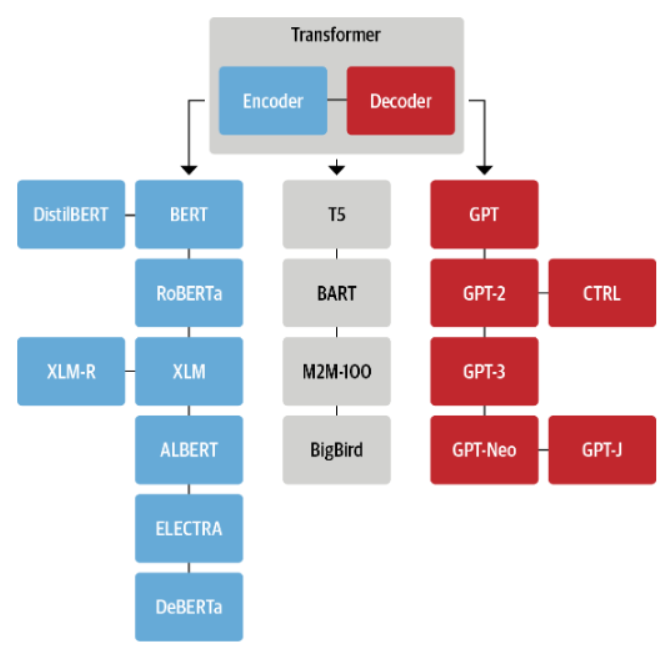

#### BERT 계열 모델을 불러와서 문장 이해 및 감성 분석 진행해보기
  - tasks(작업) : Text Classification
    - 텍스트를 입력으로 받아 텍스트가 어떤 종류의 범주에 속하는지 구분하는 작업
    - 감성 분석(sentiment-analysis) : 텍스트 내에서 사람의 기분, 감정, 의견 등을 예측하는 기술

In [ ]:
from transformers import pipeline

# transformers : 허깅페이스에서 제공되는 트랜스포머 기반 모델을 쉽게 사용할 수 있도록 도와주는 라이브러리
# pipeline : 다양한 task들을 한 줄로 수행할 수 있도록 돕는 유틸리티 함수

- 실습용 사전학습 모델 경로 : https://huggingface.co/daekeun-ml/koelectra-small-v3-nsmc
  - 네이버 영화 리뷰 데이터셋으로 학습된 KoELECTRA(한국어에 특화된 ELECTRA) 모델

In [ ]:
from transformers import pipeline

pipe = pipeline(task = "text-classification", # 작업할 단위 지정
                model= "daekeun-ml/koelectra-small-v3-nsmc", # 허깅페이스에 업로드 되어있는 모델명
                device = -1)

# device = -1 CPU 사용
# device = 0 이상 (n번째 GPU 사용)

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

#### 파이프라인 Task 종류

| 파이프라인                      | 설명                                |
| -------------------------- | --------------------------------- |
| `feature-extraction`       | 특징 추출 (텍스트에 대한 벡터 표현 추출)          |
| `fill-mask`                | 마스크 채우기                           |
| `ner`                      | 개체명 인식 (Named Entity Recognition) |
| `question-answering`       | 질의 응답                             |
| `sentiment-analysis`       | 감정 분석                             |
| `summarization`            | 요약                                |
| `text-generation`          | 텍스트 생성                            |
| `translation`              | 번역                                |
| `zero-shot-classification` | 제로샷 분류 (레이블 분류)                   |

In [ ]:
pipe('집에 가고 싶다')

# 0 : 부정, 1 : 긍정

[{'label': '0', 'score': 0.9660248160362244}]

In [ ]:
pipe(['자~~알 한다', '잘한다'])

# 여러 텍스트를 사용하고 싶다면 리스트로
# 어느 정도 뉘앙스가 부정인 경우도 분류

[{'label': '0', 'score': 0.6494434475898743},
 {'label': '1', 'score': 0.9685253500938416}]

#### Seq2Seq 계열 모델 불러와서 문장 번역 해보기

In [ ]:
# 설치되어 있는 라이브러리 삭제하기
# !pip install -q transformers

In [ ]:
# 버전 낮춰서 설치하기
!pip install -q transformers==4.45.2

In [ ]:
from transformers import pipeline

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [ ]:
import transformers
print(transformers.__version__)

4.45.2


In [ ]:
 ko_to_en = pipeline(
    task = 'translation',
    model = 'Helsinki-NLP/opus-mt-ko-en',
    device = -1
)


/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


In [ ]:
ko_to_en('아 집에 가고 싶다')

# 학습하지 않은 텍스트(ex> 사람 이름, 신조어, 은어)는 출력이 안됨

[{'translation_text': 'Oh, I want to go home.'}]

#### Zero-shot Classification(제로샷 분류)
  - 사전 훈련 자연어처리 모델을 이용해서 새로운 라벨에도 별도 학습 없이 분류를 수행하는 작업
  - 직접 라벨을 다는 것은 시간이 많이 소요되고, 도메인 지식이 필요하기 때문에 이런 작업은 실제 프로젝트에서도 많이 사용
    - 텍스트마이닝 (ex> 추상적인 topic 발견) 에서도 활용
    - 입력 문장과 후보 라벨 간의 연관성을 점수화 해서 가장 적합한 라벨 예측
  - 장점
    - 학습 데이터가 없거나 부족한 도메인에서도 즉시 분류 가능
    - 유연하게 라벨을 추가/변경할 수 있음
  - 단점
    - 복잡한 task는 성능이 저하
    - 문장 설계에 따라 결과가 민감하게 변동됨

In [ ]:
from transformers import pipeline

pipe = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli")

# BERT계열 모델
# 한국어 포함 100여개 언어 지원
# 가장 널리 쓰이는 제로샷 분류용 모델 중 하나

config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Some weights of the model checkpoint at joeddav/xlm-roberta-large-xnli were not used when initializing XLMRobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing XLMRobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

In [ ]:
# 분류할 문장 정의
sentences = [
    '확실히 포수는 성격이 좋은 사람들이 하는게 맞는듯',
    '전 재미있게 봤어요..가해자 피해자가 얽히고 뒤섞인것도 재미있고, 살기 위해 가벼움의 가면을 쓰는 주인공도 안쓰럽고, 용포 빼고 한복 색감 질감도 좋고..',
    '세계 1위 기업이랑 협력관계인게 얼마나 든든한 일인지'
]

In [ ]:
# 후보 라벨(토픽) 목록
candidate_labels = ["드라마/영화", "정치", "사회/기술", "경제", "음식", "스포츠"]

In [ ]:
# 제로샷 분류 수행
result = pipe(
    sentences, # 분류할 문장 리스트
    candidate_labels, # 예측할 토픽(라벨) 리스트
    multi_label = True # True로 하면 다중 라벨, False면 단일 라벨
)

In [ ]:
result[0]

# 'sequence' : 원본 문장
# 'labels' : 우리가 준 라벨 리스트, 확신도 기준으로 내림차순
# 'scores' : 라벨에 대한 확신도 점수

{'sequence': '확실히 포수는 성격이 좋은 사람들이 하는게 맞는듯',
 'labels': ['스포츠', '사회/기술', '정치', '경제', '드라마/영화', '음식'],
 'scores': [0.5832580924034119,
  0.5068506002426147,
  0.2444903701543808,
  0.10999505966901779,
  0.04642845317721367,
  0.006047498434782028]}

In [ ]:
for r in result:
  print(r['sequence'])
  print(r['labels'][0])
  print(r['scores'][0])

확실히 포수는 성격이 좋은 사람들이 하는게 맞는듯
스포츠
0.5832580924034119
전 재미있게 봤어요..가해자 피해자가 얽히고 뒤섞인것도 재미있고, 살기 위해 가벼움의 가면을 쓰는 주인공도 안쓰럽고, 용포 빼고 한복 색감 질감도 좋고..
드라마/영화
0.8763524889945984
세계 1위 기업이랑 협력관계인게 얼마나 든든한 일인지
경제
0.9781656861305237


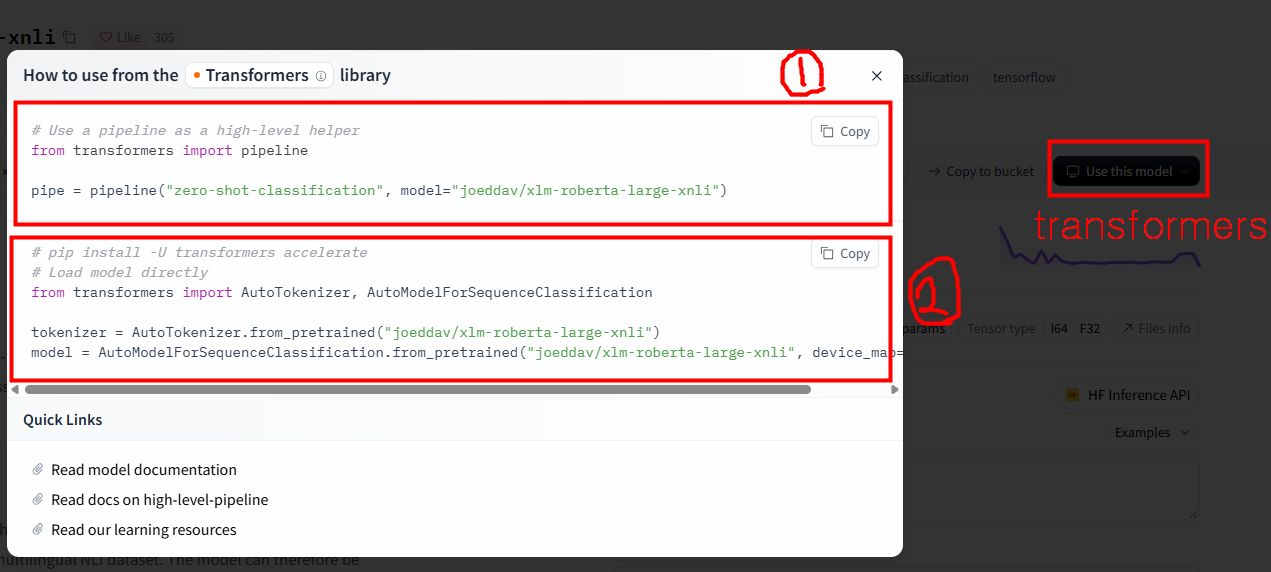

In [ ]:
# 방법 1 : 파이프라인 활용
# 방법 2 : 모델 직접 불러와서 사용

In [ ]:
# 파이프라인을 활용하면 토크나이징(토큰화) -> 모델 예측 -> 결과 해석 과정을 한번에 해결이 가능
# 장점 : 한줄로 모든 과정이 해결 가능, 자동으로 전후 처리를 해줌
# 단점 : 커스터마이징(ex> fine tunning) 불가

In [ ]:
# 모델 직접 불러와보기
# 토크나이저, 모델 로드
# 인코딩 된 입력을 모델 전달
# https://huggingface.co/monologg/koelectra-small-finetuned-nsmc

# nsmc : naver sentiment movie corpus (네이버 영화 리뷰 데이터) -> 긍정/부정 이진분류 모델

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("monologg/koelectra-small-finetuned-nsmc")
model = AutoModelForSequenceClassification.from_pretrained("monologg/koelectra-small-finetuned-nsmc")

# AutoTokenizer : 다양한 사전학습 토크나이저를 자동으로 로드해주는 도구
# AutoModelForSequenceClassification : 시퀀스 분류용 모델을 자동으로 로드해주는 도구

In [ ]:
# 예시 문장
sentences[1]

'전 재미있게 봤어요..가해자 피해자가 얽히고 뒤섞인것도 재미있고, 살기 위해 가벼움의 가면을 쓰는 주인공도 안쓰럽고, 용포 빼고 한복 색감 질감도 좋고..'

In [ ]:
# 모델을 직접 불러서 사용할때는 문장 인코딩(토큰화, 수치화)
# 문장을 모델 입력용 데이터(텐서)로 변환

encoded = tokenizer(
    sentences[1], # 인코딩할 문장(문자열) / 리스트도 가능
    padding = True, # 모든 문장을 가장 긴 문장 길이에 맞춰서 패딩 추가
    # ex> 띄어쓰기 기준 토큰화
    # '안녕 나는 연희야' -> 3개
    # '안녕하세요' -> 1개
    # '안녕하세요 0 0' -> 3개로 맞춰 주겠다
    truncation = True, # 토큰 길이가 최대 허용 길이를 초과할 경우 잘라냄
    return_tensors = 'pt'
    # 반환할 텐서 타입 지정
    # pt : pytorch 텐서 반환
    # tf : tensorflow 텐서 반환
    # list, np 등
)

In [ ]:
encoded

# 'input_ids' : 텍스트 데이터를 수치화 한 값
# 토큰 ID 부여, 주어진 문장을 모델이 이해할 수 있는 정수 ID 시퀀스로 변환한 결과
# 여기서 2,3은 특별 토큰 -> 시작[CLS], 끝[SEP]을 나타내는 토큰
# CLS : classify 토큰 -> 문장의 시작에 추가
# SEP : seperator 토큰 -> 문장의 끝에 추가

# 'token_type_ids' : 문장을 구분하는 id, 첫 번째 문장은 0, 두 번째 문장은 1, 세 번째 문장은 2,...
# 현재는 한 문장만 부여했으므로 0만 있음
# 문장이 두 개 이상인 입력에서 각 토큰이 어떤 문장에 속하는지 나타내는 id

# 'attention_mask' : 패딩(mask) 위치 표시
# 모델이 주의(attend)해야하는지 여부를 나타내는 마스크
# 토큰이 실제 내용이면 1, 패딩으로 채워진 토큰이면 0
# 현재는 부여된 패딩이 없으므로 모든 위치가 1

{'input_ids': tensor([[    2,  3878, 31215,  2384, 11132,    18,    18, 14366,  5675, 19631,
          3452, 15040,  1286,  7243,  5723, 13813, 12792, 16811,    16, 23868,
         10574, 16305,  6303,  5829, 14185,  5703, 12858, 12228,  5668,  3364,
          5955, 24072,    16,  3624,  5925, 21760, 22054,  2818,  6036,  4120,
         19614, 16943,    18,    18,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [ ]:
encoded['input_ids'][0]

tensor([    2,  3878, 31215,  2384, 11132,    18,    18, 14366,  5675, 19631,
         3452, 15040,  1286,  7243,  5723, 13813, 12792, 16811,    16, 23868,
        10574, 16305,  6303,  5829, 14185,  5703, 12858, 12228,  5668,  3364,
         5955, 24072,    16,  3624,  5925, 21760, 22054,  2818,  6036,  4120,
        19614, 16943,    18,    18,     3])

In [ ]:
# 토큰 목록 확인
# 토큰들을 다시 자연어로 돌려보기
# 각 정수 ID가 어떤 토큰에 매칭되는지 확인
tokenizer.convert_ids_to_tokens(encoded['input_ids'][0])

# ##으로 시작하는 토큰 : 앞에 토큰과 붙어서 하나의 단어로 이어지는(subword) 토큰

# 전체 단어 대신 subword(자주 쓰이는 어절 조각) 단위로 어휘(vocabulary)를 구성 -> wordpiece
# ex> playing -> play + ##ing, unhappiness -> un + ##happi + ##ness

# 대부분의 허깅페이스 모델은 워드피스 기반 모델
# 워드피스 기반 모델 : 문장 -> 서브워드 조각 -> 정수 시퀀스로 바꿔주는 구글 표준 서브워드 토크나이저를 쓰는 모델

# 왜?
# OOV(out of vocabulary) 감소 : 미리 정의된 어휘에 없는 단어도 서브워드 조합으로 표현 가능
# 어휘 크기 절감 : 전체 단어를 다 담기보다 자주 쓰이는 조각만 모아 어휘 수 감소
# 희귀어 처리 : 드물게 쓰이는 단어도 공통된 접두, 접미사 조각 덕분에 의미 파악

# ex> 단어 토큰 : eat, ing
# 새로 학습할 단어 eating
# 3개의 단어 사전을 만들 필요 없이 기존의 단어 토큰으로 의미 유추가 가능하다!

['[CLS]',
 '전',
 '재미있게',
 '봤',
 '##어요',
 '.',
 '.',
 '가해',
 '##자',
 '피해자가',
 '얽',
 '##히고',
 '뒤',
 '##섞',
 '##인',
 '##것도',
 '재미',
 '##있고',
 ',',
 '살기',
 '위해',
 '가벼',
 '##움',
 '##의',
 '가면',
 '##을',
 '쓰는',
 '주인공',
 '##도',
 '안',
 '##쓰',
 '##럽고',
 ',',
 '용',
 '##포',
 '빼고',
 '한복',
 '색',
 '##감',
 '질',
 '##감도',
 '좋고',
 '.',
 '.',
 '[SEP]']

In [ ]:
# 모델 설정 확인(모델 설명)
model.config

ElectraConfig {
  "_name_or_path": "monologg/koelectra-small-finetuned-nsmc",
  "_num_labels": 2,
  "architectures": [
    "ElectraForSequenceClassification"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "embedding_size": 128,
  "finetuning_task": "nsmc",
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 256,
  "id2label": {
    "0": "negative",
    "1": "positive"
  },
  "initializer_range": 0.02,
  "intermediate_size": 1024,
  "label2id": {
    "negative": 0,
    "positive": 1
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "electra",
  "num_attention_heads": 4,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "summary_activation": "gelu",
  "summary_last_dropout": 0.1,
  "summary_type": "first",
  "summary_use_proj": true,
  "transformers_version": "4.45.2",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 32200
}

- config 설명

| 속성                             | 설명                                                        |
| ------------------------------ | --------------------------------------------------------- |
| `model_type`                   | 모델 유형 (`"electra"`)                                       |
| `architectures`                | 로드된 모델 클래스 이름 (`["ElectraForSequenceClassification"]`)    |
| `vocab_size`                   | 어휘 사전 크기 (토크나이저가 사용하는 토큰 개수)                              |
| `embedding_size`               | 임베딩 차원 수 (토큰 임베딩 벡터의 크기)                                  |
| `hidden_size`                  | Transformer 블록 내부 피처 차원 수                                 |
| `num_hidden_layers`            | 인코더(혹은 디코더) 레이어 개수                                        |
| `num_attention_heads`          | 어텐션 헤드 수                                                  |
| `intermediate_size`            | Feed-Forward 네트워크의 은닉층 차원 수                               |
| `hidden_act`                   | 은닉층 활성화 함수 (`"gelu"`)                                     |
| `layer_norm_eps`               | LayerNorm 안정화를 위한 작은 값                                    |
| `position_embedding_type`      | 위치 임베딩 방식 (`"absolute"`)                                  |
| `max_position_embeddings`      | 시퀀스 길이 최대값 (위치 임베딩 개수)                                    |
| `type_vocab_size`              | 세그먼트(토큰 타입) 임베딩 크기                                        |
| `pad_token_id`                 | 패딩 토큰 ID                                                  |
| `use_cache`                    | 디코더에서 이전 키·값 캐싱 사용 여부                                     |
|                                |                                                           |
| **드롭아웃 관련**                    |                                                           |
| `attention_probs_dropout_prob` | 어텐션 확률 드롭아웃 비율                                            |
| `hidden_dropout_prob`          | 은닉층 드롭아웃 비율                                               |
| `classifier_dropout`           | 분류기 헤드 드롭아웃 비율 (여기선 `null` → 기본 `hidden_dropout_prob` 사용) |
|                                |                                                           |
| **레이블 매핑**                     |                                                           |
| `id2label`                     | 예측된 정수 레이블을 문자열로 매핑 (`0→"negative"`, `1→"positive"`)      |
| `label2id`                     | 문자열 레이블을 정수로 매핑 (`"negative"→0`, `"positive"→1`)          |
|                                |                                                           |
| **기타**                         |                                                           |
| `initializer_range`            | 가중치 초기화 시 표준편차                                            |
| `finetuning_task`              | 파인튜닝 목적 태스크 이름 (`"nsmc"`)                                 |
| `torch_dtype`                  | 모델 내부 연산에 사용하는 텐서 자료형 (`"float32"`)                       |
| `transformers_version`         | 이 설정을 만든 Transformers 라이브러리 버전                            |


In [ ]:
# 인덱스 번호별 레이블 확인
model.config.id2label

{0: 'negative', 1: 'positive'}

In [ ]:
# 인코딩 된 입력값을 모델에 전달
outputs = model(**encoded)
outputs
# model(input_ids = encoded['input_ids'],
#       token_type_ids = encoded['token_type_ids'],
#       attention_mask = encoded['attention_mask'])

# **를 붙이면 딕셔너리 key, value 값이 각각 함수로 전달


# loss : 학습 시 레이블을 넣으면 계산되는 손실값 (따로 설정을 안해서 None)
# logits : 모델이 계산한 원시 점수(softmax 함수에 입력되는 값)

SequenceClassifierOutput(loss=None, logits=tensor([[-2.6420,  2.4065]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

In [ ]:
def addnum(num1, num2, *num):
  print(num)
  return num1 + num2

In [ ]:
# 키워드 가변 매개변수 (**kwargs)
def temp(**kwargs):
  return kwargs

In [ ]:
outputs.logits
# 각 클래스별 점수
# 높을 수록 해당 클래스일 확률이 높다 -> 1(긍정)일 확률이 높아보임

tensor([[-2.6420,  2.4065]], grad_fn=<AddmmBackward0>)

In [ ]:
# 확률로 변환해보기 -> softmax 함수 적용

import torch.nn.functional as F
# pytoch의 기능적 인터페이스를 제공하는 모듈 -> 다양한 신경망 함수(활성화함수, 손실함수, 변환 등)

In [ ]:
# 로짓을 확률로 전환
probs = F.softmax(
    outputs.logits
)

probs

/tmp/ipykernel_29974/657027019.py:2: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  probs = F.softmax(


tensor([[0.0064, 0.9936]], grad_fn=<SoftmaxBackward0>)

In [ ]:
# 예측 레이블(가장 높은 확률을 가진 클래스) 추출
probs[0].argmax()

tensor(1)